# 01 · Motor de Dados — baixando candles da XM pelo MT5

**LHS Quant Lab · Fase 1 (Dados)**

## 🎯 Objetivo
Entender, passo a passo, como o projeto pega os preços do MetaTrader 5 e guarda no computador.
No fim você vai saber exatamente o que a **rotina automática diária** faz por trás.

## 📚 O que você vai aprender
| Parte | Assunto |
|---|---|
| 1 | Preparar o notebook (bibliotecas e pasta do projeto) |
| 2 | Conectar ao MT5 e **conferir a conta** |
| 3 | Baixar candles de **um** par e **um** timeframe |
| 4 | Transformar os dados numa tabela (DataFrame) |
| 5 | Entender **pip, ponto, tick e spread** na XM |
| 6 | Ver os candles num gráfico |
| 7 | Salvar em Parquet |
| 8 | Usar o módulo do projeto (o mesmo da rotina automática) |
| 9 | Checar a qualidade dos dados |
| 10 | Conclusões e exercícios |

## ▶️ Como rodar
- Kernel: **financeiro** (canto superior direito do VS Code).
- Rode uma célula por vez com **Shift + Enter** e leia a explicação antes de cada uma.
- O MetaTrader 5 da XM precisa estar **aberto**.

> 🔒 **Segurança:** este notebook só **lê** preços. Nenhuma célula envia ordens.

---
## 1 · Preparando o notebook

**O que este bloco faz**
- Importa as bibliotecas:
  - `MetaTrader5` → conversa com o terminal MT5 aberto no seu PC;
  - `pandas` → trabalha com tabelas (linhas = candles, colunas = preços);
  - `Path` → monta caminhos de pastas sem se preocupar com barras `\` ou `/`.
- Descobre a **pasta raiz do projeto** e adiciona `src/` ao Python, para podermos importar o nosso módulo `lhsquant`.

In [1]:
import sys
from pathlib import Path

import MetaTrader5 as mt5
import pandas as pd

# A raiz do projeto é a pasta que contém 'src' (funciona rodando da raiz ou de notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

pd.set_option("display.width", 120)
print("Pasta do projeto:", RAIZ)

Pasta do projeto: c:\Dev\GitHub\LHS Capital\lhs-quant-lab


---
## 2 · Conectando ao MT5 e conferindo a conta

**O que este bloco faz**
- `mt5.initialize()` conecta ao terminal **que já está aberto**. Ele usa a conta que estiver logada lá, que pode ser a **demo** ou a **real**.
- `mt5.account_info()` mostra o servidor, o login e o tipo da conta (`trade_mode`: 0 = demo, 2 = real).

**Por que conferir?** É uma regra de segurança do projeto: sempre saber em qual conta estamos.
Para **ler preços** não há risco em nenhuma das duas, mas para qualquer coisa além disso **só a demo**.

In [2]:
if not mt5.initialize():
    raise RuntimeError(f"Não conectou. O MT5 está aberto? Erro: {mt5.last_error()}")

conta = mt5.account_info()
tipo = {0: "DEMO", 1: "CONCURSO", 2: "REAL"}[conta.trade_mode]
print(f"Servidor: {conta.server} | Login: {conta.login} | Conta: {tipo}")
print("Máx. barras por pedido:", mt5.terminal_info().maxbars)

Servidor: XMGlobal-MT5 15 | Login: XXXXXXXX | Conta: REAL
Máx. barras por pedido: 1000000


💡 **Máx. barras** é o limite de candles que o terminal entrega de uma vez.
Para ter mais histórico: no MT5, *Ferramentas → Opções → Gráficos → Máx. barras no gráfico → Ilimitado*.

---
## 3 · Baixando candles de um par

**O que este bloco faz**
- `symbol_select("EURUSD", True)` garante que o par está na *Observação do Mercado* (sem isso o MT5 pode não entregar dados).
- `copy_rates_from_pos(símbolo, timeframe, início, quantidade)` pede os candles:
  - `início = 0` → começa do candle **mais recente** e volta no tempo;
  - `quantidade = 500` → os últimos 500 candles.
- O resultado vem num formato "cru" do MT5 (um *array*). Mostramos só as 3 primeiras linhas.

In [3]:
SIMBOLO = "EURUSD"
TIMEFRAME = mt5.TIMEFRAME_H1  # experimente depois: TIMEFRAME_M15, TIMEFRAME_D1 ...

mt5.symbol_select(SIMBOLO, True)
rates = mt5.copy_rates_from_pos(SIMBOLO, TIMEFRAME, 0, 500)

print("Candles recebidos:", len(rates))
rates[:3]

Candles recebidos: 500


array([(1789981200, 1.14722, 1.14781, 1.14701, 1.14737, 1970, 16, 0),
       (1789984800, 1.14738, 1.14775, 1.14698, 1.14751, 2202, 16, 0),
       (1789988400, 1.14752, 1.14852, 1.14736, 1.1479 , 2217, 16, 0)],
      dtype=[('time', '<i8'), ('open', '<f8'), ('high', '<f8'), ('low', '<f8'), ('close', '<f8'), ('tick_volume', '<u8'), ('spread', '<i4'), ('real_volume', '<u8')])

In [4]:
df = pd.DataFrame(rates)
df["time"] = pd.to_datetime(df["time"], unit="s")
df = (
    df.rename(
        columns={
            "time": "tempo",
            "open": "abertura",
            "high": "maxima",
            "low": "minima",
            "close": "fechamento",
        }
    )
    .set_index("tempo")
    .iloc[:-1]
)  # tira o candle que ainda não fechou

df.tail()

,abertura,maxima,minima,fechamento,tick_volume,spread,real_volume
tempo,,,,,,,
2026-10-19 23:00:00,1.12104,1.12118,1.12080,1.12091,690,16,0
2026-10-20 00:00:00,1.12102,1.12125,1.12059,1.12121,228,31,0
2026-10-20 01:00:00,1.12121,1.12132,1.12109,1.12111,488,16,0
2026-10-20 02:00:00,1.12111,1.12131,1.12102,1.12126,483,16,0
2026-10-20 03:00:00,1.12126,1.12185,1.12125,1.12146,1797,16,0


**Lendo as colunas**
| Coluna | Significado |
|---|---|
| abertura / maxima / minima / fechamento | os 4 preços do candle (OHLC) |
| tick_volume | quantas vezes o preço mudou no candle (forex não tem volume central) |
| spread | diferença compra/venda **em pontos** naquele candle |
| real_volume | volume real; no forex da XM costuma ser 0 |

---
## 5 · Pip, ponto, tick e spread na XM

Para calcular **metas, stops e lote** precisamos saber quanto vale cada movimento do preço **em dinheiro**.

| Termo | O que é | EURUSD (5 dígitos) |
|---|---|---|
| Ponto | menor casa decimal do preço | 0,00001 |
| Pip | 10 pontos (convenção do forex) | 0,0001 |
| Tick value | quanto vale **1 ponto** com **1 lote** | ~US$ 1 |
| Spread | custo de entrar (compra − venda) | em pontos |

**O que este bloco faz:** lê essas informações da corretora com `symbol_info` e calcula o **valor de 1 pip por lote**.

In [5]:
info = mt5.symbol_info(SIMBOLO)

pip = info.point * 10 if info.digits in (3, 5) else info.point
valor_pip_lote = info.trade_tick_value * (pip / info.trade_tick_size)

print(f"Dígitos: {info.digits} | Ponto: {info.point} | Pip: {pip}")
print(f"Valor de 1 pip com 1 lote: {valor_pip_lote:.2f} {info.currency_profit}")
print(f"Spread agora: {info.spread} pontos = {info.spread / 10:.1f} pips")
print(f"Spread médio dos últimos candles: {df['spread'].mean() / 10:.1f} pips")

Dígitos: 5 | Ponto: 1e-05 | Pip: 0.0001
Valor de 1 pip com 1 lote: 10.00 USD
Spread agora: 22 pontos = 2.2 pips
Spread médio dos últimos candles: 1.8 pips


💡 **Exemplo prático:** no EURUSD, 1 pip com 1 lote vale cerca de US$ 10. Com stop de 20 pips e 0,10 lote:
risco = 20 pips × US$ 10 × 0,10 lote = **US$ 20**. Use o valor impresso acima, porque é o da sua corretora.

⚠️ Pares com USD na frente (USDJPY, USDCAD) têm o valor do pip **variando com o preço**. Por isso a rotina diária guarda esses dados **todo dia**, no arquivo `info_simbolos.parquet`.

---
## 6 · Vendo os candles

**O que este bloco faz:** desenha os últimos 120 candles com a biblioteca `mplfinance`.
Ela exige as colunas em inglês (`Open`, `High`...), então renomeamos **só para o gráfico**.
`mav=(20, 50)` adiciona as médias móveis de 20 e 50 períodos.

findfont: Failed to find font weight semibold, now using 700.


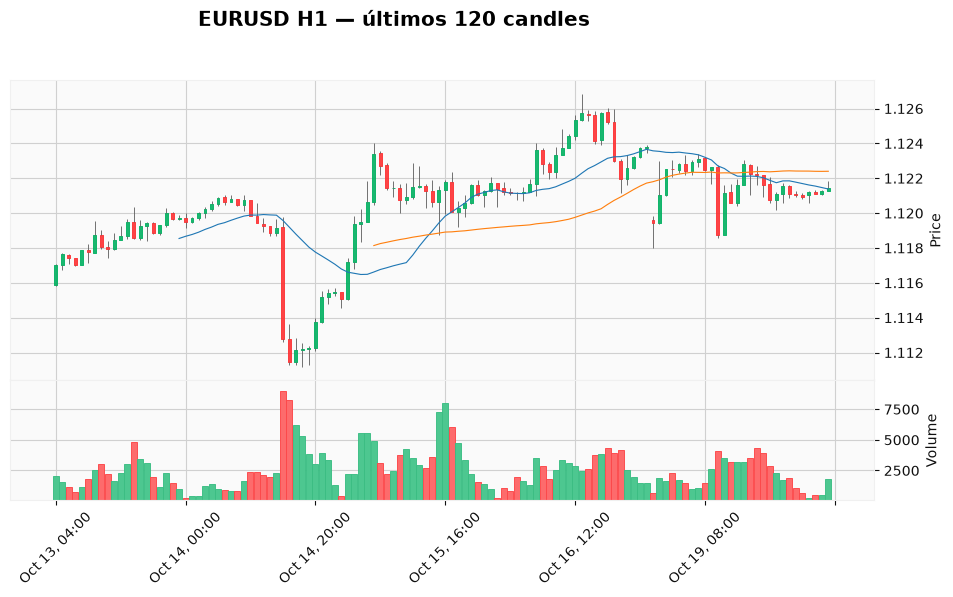

In [6]:
import mplfinance as mpf

grafico = df.rename(
    columns={
        "abertura": "Open",
        "maxima": "High",
        "minima": "Low",
        "fechamento": "Close",
        "tick_volume": "Volume",
    }
)
mpf.plot(
    grafico.tail(120),
    type="candle",
    style="yahoo",
    mav=(20, 50),
    volume=True,
    figsize=(12, 6),
    title=f"{SIMBOLO} H1 — últimos 120 candles",
)

---
## 7 · Salvando em Parquet

**Por que Parquet e não Excel/CSV?**
- É **muito menor** (compactado) e **muito mais rápido** para ler.
- Guarda os **tipos** certos (datas continuam datas, números continuam números).

**O que este bloco faz:** salva numa pasta de **testes** (para não misturar com os dados oficiais), lê de volta e confere se ficou igual.

In [7]:
pasta_teste = RAIZ / "dados" / "teste_notebook"
pasta_teste.mkdir(parents=True, exist_ok=True)
arquivo = pasta_teste / f"{SIMBOLO}_H1.parquet"

df.to_parquet(arquivo)
lido = pd.read_parquet(arquivo)

print("Arquivo:", arquivo.name, f"| {arquivo.stat().st_size / 1024:.0f} KB")
print("Igual ao original?", lido.equals(df))

Arquivo: EURUSD_H1.parquet | 27 KB
Igual ao original? True


---
## 8 · O módulo do projeto (o que roda todo dia sozinho)

Tudo o que fizemos à mão está organizado em `src/lhsquant/dados.py`:

| Função | O que faz |
|---|---|
| `conectar()` | conecta e mostra a conta |
| `baixar(simbolo, tf)` | partes 3 e 4 juntas |
| `atualizar(simbolo, tf)` | lê o Parquet salvo e baixa **só os candles novos** (incremental) |
| `salvar_info_simbolos()` | parte 5 para todos os pares, guardando o histórico diário |
| `atualizar_tudo()` | roda tudo para os 6 símbolos × 6 timeframes |

A tarefa agendada do Windows roda `scripts/atualizar_dados.py`, que chama `atualizar_tudo()` e grava um log em `logs/`.

**O que este bloco faz:** mostra o **inventário** dos dados já salvos: quantos candles e de quando até quando.
É um resumo compacto: o Python faz a conta e mostra só o essencial.

In [8]:
from lhsquant import dados

linhas = []
for simbolo in dados.SIMBOLOS:
    for tf in dados.TIMEFRAMES:
        arq = dados.caminho(simbolo, tf)
        if arq.exists():
            d = pd.read_parquet(arq, columns=["fechamento"])
            linhas.append(
                {
                    "simbolo": simbolo,
                    "tf": tf,
                    "candles": len(d),
                    "inicio": d.index[0].date(),
                    "fim": d.index[-1],
                }
            )
inventario = pd.DataFrame(linhas)
inventario.pivot(index="simbolo", columns="tf", values="inicio")[list(dados.TIMEFRAMES)]

tf,M1,M5,M15,H1,H4,D1
simbolo,,,,,,
AUDUSD,2026-07-10,2025-06-12,2022-10-06,2010-09-02,1993-04-27,1993-04-27
BTCUSD,2026-07-18,2025-11-01,2023-12-07,2013-01-02,2013-01-02,2013-01-02
EURUSD,2026-07-10,2025-06-12,2022-10-06,2010-09-02,1971-01-04,1971-01-04
GBPUSD,2026-05-12,2025-04-14,2022-10-06,2010-09-02,1993-05-12,1993-05-12
USDCAD,2026-07-10,2025-06-12,2022-10-06,2010-09-03,1993-04-28,1993-04-28
USDJPY,2026-05-12,2025-04-14,2022-10-06,2010-09-02,1971-01-04,1971-01-04


👆 A tabela mostra **a data do candle mais antigo** de cada par e timeframe.
Repare que M1 começa bem mais recente que D1: é o limite de barras do terminal.

---
## 9 · Checando a qualidade dos dados

Dados ruins geram backtests mentirosos. Três checagens simples no **EURUSD H1** salvo:

1. **Candles repetidos** (mesmo horário duas vezes) → devem ser 0.
2. **Preços impossíveis** (máxima menor que a mínima) → devem ser 0.
3. **Buracos**: intervalos maiores que o normal entre candles. Fins de semana são esperados (cerca de 48 h); outros buracos merecem atenção.

In [9]:
h1 = pd.read_parquet(dados.caminho("EURUSD", "H1"))

repetidos = h1.index.duplicated().sum()
impossiveis = (h1["maxima"] < h1["minima"]).sum()
intervalos = h1.index.to_series().diff().dropna()
buracos = intervalos[intervalos > pd.Timedelta(hours=1)]
fds = buracos[
    buracos.index.dayofweek == 0
]  # buraco que termina na segunda = fim de semana

print(f"Candles: {len(h1):,} | de {h1.index[0]:%Y-%m-%d} a {h1.index[-1]:%Y-%m-%d}")
print(f"Repetidos: {repetidos} | Máxima < mínima: {impossiveis}")
print(
    f"Buracos > 1h: {len(buracos)} (fins de semana: {len(fds)}, outros: {len(buracos) - len(fds)})"
)
print("Maiores buracos fora do fim de semana:")
print(buracos.drop(fds.index).sort_values(ascending=False).head(5).to_string())

Candles: 100,017 | de 2010-09-02 a 2026-10-16
Repetidos: 0 | Máxima < mínima: 0
Buracos > 1h: 859 (fins de semana: 800, outros: 59)
Maiores buracos fora do fim de semana:
tempo
2018-01-02 09:00:00   3 days 10:00:00
2017-12-26 09:00:00   3 days 10:00:00
2024-01-02 00:00:00   3 days 01:00:00
2023-12-26 00:00:00   3 days 01:00:00
2022-12-27 00:00:00   3 days 01:00:00


💡 Buracos fora do fim de semana costumam ser **feriados** (Natal, Ano Novo) ou falhas no histórico da corretora.
Alguns poucos é normal; muitos indicam que vale buscar outra fonte (ex.: Dukascopy).

In [10]:
mt5.shutdown()  # sempre desconectar no fim
print("Desconectado do MT5.")

Desconectado do MT5.


---
## 10 · ✅ Conclusões

1. O MT5 entrega candles com `copy_rates_from_pos`; o tempo vem em segundos e precisa ser convertido.
2. **O último candle está aberto** e deve ser descartado, ou o backtest "vê o futuro".
3. Horários são do **servidor da XM** (GMT+2/+3).
4. O valor do pip vem da corretora (`trade_tick_value`) e **muda** em pares com USD na frente. Por isso guardamos isso todo dia.
5. **Parquet** é o formato do projeto: pequeno, rápido e fiel aos tipos.
6. A rotina diária faz tudo isso sozinha e baixa **só o que é novo**.
7. Antes de confiar nos dados, checar **repetidos, preços impossíveis e buracos**.

## 🏋️ Exercícios
1. Troque `SIMBOLO` para `"USDJPY"` e rode as partes 3 a 5. Quanto vale 1 pip por lote? Por que o pip tem 3 casas aqui?
2. Na parte 3, troque para `TIMEFRAME_D1` e baixe 1000 candles. Até que ano chegou?
3. Rode a parte 9 para o `BTCUSD` em H1. Ele tem buracos de fim de semana? Por quê?
4. Calcule o spread médio (em pips) de cada hora do dia no EURUSD H1. Dica: `h1.groupby(h1.index.hour)["spread"].mean() / 10`. Em que horário operar é mais caro?

➡️ **Próximo notebook:** `02` — explorando os dados: retornos, volatilidade por horário e por par.